# Customer Segmentation via Spectral Clustering
### A comparison of Spectral, K-Means and Agglomerative clustering on Online Retail II

**Aim.** Group the customers of a UK online gift retailer by *which products they buy*, compare three clustering
families, and turn the groups into segments a business can act on.

**How to run.** `Kernel > Restart & Run All`. Put `online_retail_II.csv` in `../data/`. If it is missing, the notebook
falls back to the small synthetic demo file so that it still runs, and says so in the next cell. The run with the real
file takes roughly 5 minutes (t-SNE and the spectral methods are the slow parts). Every random step uses `seed = 42`,
so a second run gives identical numbers.

**Pipeline.**
1. Load and clean the transactions
2. Build the customer x product matrix
3. L2-normalise and reduce with Truncated SVD
4. Choose k
5. Cluster (spectral variants, K-Means, agglomerative)
6. Evaluate with Silhouette, Davies-Bouldin and Calinski-Harabasz
7. Visualise with PCA and t-SNE
8. Test the similarity measure (cosine and Jaccard against Euclidean)
9. Profile the segments (spend, frequency, variety, representative products)
10. Group products for cross-selling

**Acknowledgement.** The overall design (clean, customer x product matrix, L2 + SVD, three algorithms, three metrics) follows an
earlier student project on the same dataset by Shrushti. The cleaning rules, the sparse matrix, the extra spectral variants, the
profiling, the product grouping, the dashboard and the tests in this repository are new work, and section 2 documents a bug that
was found in the earlier cleaning step.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore", message="Graph is not fully connected")
sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from retail_clustering import (data, features, clustering, evaluation,
                               plots, products, profiling)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
SEED = 42

REAL = "../data/online_retail_II.csv"
DEMO = "../data/synthetic_retail.csv"
DATA_PATH = REAL if os.path.exists(REAL) else DEMO
USING_DEMO = DATA_PATH == DEMO
print("Using:", DATA_PATH)
if USING_DEMO:
    print("WARNING: real dataset not found. These results come from SYNTHETIC demo data and must not be reported.")

Using: ../data/online_retail_II.csv


## 1. Load the data

`Online Retail II` (Chen, 2015) holds about 1.07 million invoice lines from December 2009 to December 2011. Columns: invoice number,
stock code, description, quantity, invoice date, unit price, anonymised customer id and country. The data are public, anonymised and
licensed CC BY 4.0, so no ethical approval beyond the department's standard secondary-data statement (category A0, C0) is needed.

In [2]:
raw = data.load_transactions(DATA_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

1,067,371 rows x 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# Quick look at the problems the cleaning step must deal with
summary = pd.DataFrame({
    "cancelled invoices (start with C)": [raw["Invoice"].astype(str).str.startswith("C").sum()],
    "quantity <= 0": [(raw["Quantity"] <= 0).sum()],
    "price <= 0": [(raw["Price"] <= 0).sum()],
    "missing Customer ID": [raw["Customer ID"].isna().sum()],
    "non-product stock codes": [(~raw["StockCode"].astype(str).str.match(data.PRODUCT_CODE)).sum()],
}).T.rename(columns={0: "rows"})
summary

,rows
cancelled invoices (start with C),19494
quantity <= 0,22950
price <= 0,6207
missing Customer ID,243007
non-product stock codes,6094


## 2. Clean the data

Four kinds of row are removed: cancellations, non-positive quantity or price, rows with no customer id, and non-product lines
(postage, bank charges, manual adjustments, fees). A real product code is five digits with an optional one or two letter suffix
(for example `85123A`), so that pattern is used to keep products and drop everything else.

The row count after every step is recorded so that each rule can be checked.

In [4]:
df, report = data.clean_transactions(raw)
pd.Series(report, name="rows").to_frame().assign(removed=lambda t: (-t["rows"].diff()).fillna(0).astype(int))

,rows,removed
raw rows,1067371,0
after removing cancellations,1047877,19494
after removing qty/price <= 0,1041670,6207
after dropping missing Customer ID,805549,236121
after keeping real product codes,802632,2917


### A bug in the earlier approach

The earlier project removed non-product lines by searching the *description* with the pattern
`POSTAGE|DISCOUNT|ADJUSTMENT|M|DOTCOM`. The lone `M` matches **any description containing a capital M**, which removes genuine
products. The next cell measures the damage on the cleaned data.

In [5]:
old_pattern = "POSTAGE|DISCOUNT|ADJUSTMENT|M|DOTCOM"
wrongly_removed = df[df["Description"].astype(str).str.contains(old_pattern, na=False)]
print(f"Real product lines the old description filter would delete: {len(wrongly_removed):,} "
      f"({len(wrongly_removed) / len(df):.1%} of the cleaned data)")
print("Examples of products it would lose:")
print(wrongly_removed["Description"].drop_duplicates().head(8).to_string(index=False))

Real product lines the old description filter would delete: 334,616 (41.7% of the cleaned data)
Examples of products it would lose:
15CM CHRISTMAS GLASS BALL 20 LIGHTS
       RECORD FRAME 7" SINGLE SIZE 
     STRAWBERRY CERAMIC TRINKET BOX
                SAVE THE PLANET MUG
 FANCY FONT HOME SWEET HOME DOORMAT
       HEART MEASURING SPOONS LARGE
              DOOR MAT BLACK FLOCK 
           HOME BUILDING BLOCK WORD


In [6]:
# Automated sanity checks after cleaning (from the project's risk plan)
assert df["Customer ID"].notna().all()
assert (df["Quantity"] > 0).all() and (df["Price"] > 0).all()
assert not df["Invoice"].astype(str).str.startswith("C").any()
assert df["StockCode"].str.match(data.PRODUCT_CODE).all()
print("All cleaning checks passed.")
print(f"{df['Customer ID'].nunique():,} customers, {df['StockCode'].nunique():,} products, "
      f"{df['Invoice'].nunique():,} invoices")

All cleaning checks passed.
5,852 customers, 4,619 products, 36,594 invoices


## 3. Customer x product matrix

Each customer becomes a row and each product a column. Three choices matter:

* **Values.** `binary` (bought or not) is the default. `invoices` counts the separate orders containing the product, so it captures *how often*;
  `log-invoices` softens very frequent items.
* **Filtering.** Keep products bought by at least `MIN_CUSTOMERS_PER_PRODUCT` customers and customers who bought at least
  `MIN_PRODUCTS_PER_CUSTOMER` different products. One-off activity adds noise, not behavioural signal.
* **Sampling.** Spectral clustering builds a customer x customer graph, so memory grows with the square of the number of customers.
  A sample of `MAX_CUSTOMERS` customers and the `MAX_PRODUCTS` most popular products keeps it fast.

In [7]:
WEIGHTING = "binary"             # "binary" | "invoices" | "log-invoices"
MIN_PRODUCTS_PER_CUSTOMER = 20
MIN_CUSTOMERS_PER_PRODUCT = 50
MAX_CUSTOMERS, MAX_PRODUCTS = 2000, 500
N_COMPONENTS = 50

M_full, customers_full, products_full = features.build_customer_product_matrix(
    df, MIN_PRODUCTS_PER_CUSTOMER, MIN_CUSTOMERS_PER_PRODUCT, WEIGHTING)
print("After filtering:", M_full.shape)

M, customers, prods = features.sample_matrix(M_full, customers_full, products_full,
                                              MAX_CUSTOMERS, MAX_PRODUCTS, SEED)
density = (M > 0).nnz / (M.shape[0] * M.shape[1])
print(f"Sampled matrix: {M.shape}, {density:.1%} of cells are non-zero")

After filtering: (4219, 2385)
Sampled matrix: (2000, 500), 9.5% of cells are non-zero


## 4. L2 normalisation and Truncated SVD

L2-normalising each row gives it length 1, so two customers who buy the same *mix* of products end up close together whether
one buys in bulk or not. Truncated SVD then compresses the sparse product columns into a small dense representation that
keeps the dominant structure and removes noise, which the clustering algorithms handle far better.

In [8]:
X, explained = features.reduce_features(M, N_COMPONENTS, SEED)
print(f"Reduced representation: {X.shape}; variance kept: {explained:.1%}")
fs = features.make_features(df, MIN_PRODUCTS_PER_CUSTOMER, MIN_CUSTOMERS_PER_PRODUCT,
                            MAX_CUSTOMERS, MAX_PRODUCTS, N_COMPONENTS, SEED, WEIGHTING)
assert np.allclose(fs.X_reduced, X)        # the packaged function does exactly the steps above

Reduced representation: (2000, 50); variance kept: 36.3%


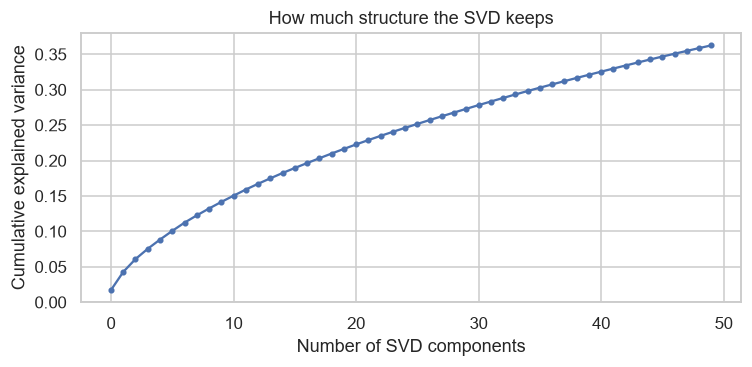

In [9]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
svd = TruncatedSVD(N_COMPONENTS, random_state=SEED).fit(normalize(M))
plt.figure(figsize=(7, 3.5))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker="o", markersize=3)
plt.xlabel("Number of SVD components"); plt.ylabel("Cumulative explained variance")
plt.title("How much structure the SVD keeps"); plt.tight_layout(); plt.show()

## 5. Choosing the number of clusters

K-Means is fitted for k = 2 to 10 and the silhouette score is plotted. A clear peak would justify a value of k; a flat line means the
data do not favour one, and k has to be chosen for interpretability instead.

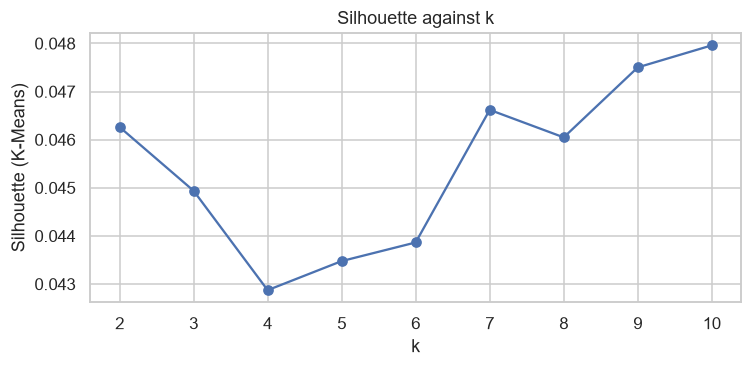

Highest at k = 10; spread between best and worst = 0.005


In [10]:
sweep = clustering.sweep_k(fs.X_reduced, range(2, 11), SEED)
plt.figure(figsize=(7, 3.5))
plt.plot(list(sweep), list(sweep.values()), marker="o")
plt.xlabel("k"); plt.ylabel("Silhouette (K-Means)"); plt.title("Silhouette against k"); plt.tight_layout(); plt.show()
print(f"Highest at k = {max(sweep, key=sweep.get)}; spread between best and worst = "
      f"{max(sweep.values()) - min(sweep.values()):.3f}")

**Reading the chart.** If the spread is only a few thousandths, as it is on the real data, silhouette cannot separate one k from another.
The analysis therefore uses **k = 6**, a value large enough to give distinct segments and small enough to read, and checks other values
in the dashboard.

## 6. Clustering

All methods receive the same reduced matrix and the same k so they can be compared fairly.

| Method | Idea |
|---|---|
| K-Means | Moves k centres to the middle of their members; assumes compact, round clusters |
| Agglomerative (Ward) | Merges the closest clusters bottom-up until k remain |
| Spectral, kNN graph | Links each customer to its nearest neighbours, takes eigenvectors of the graph Laplacian, then clusters those; can follow non-convex shapes |
| Spectral, RBF kernel | Same idea with every pair linked by a distance-based weight |
| Spectral, cosine / Jaccard kNN | Same graph idea with angle-based or basket-overlap similarity (tests the similarity measure) |

The two label-assignment methods for spectral clustering (`kmeans` and `discretize`) are both included to show how sensitive the
algorithm is to its own settings.

In [11]:
K = 6
labels = clustering.run_all(fs.X_reduced, K, n_neighbors=10, M=fs.binary, seed=SEED)
pd.DataFrame({m: np.bincount(l, minlength=K) for m, l in labels.items()}).T.rename_axis("Method")

,0,1,2,3,4,5
Method,,,,,,
"Spectral (kNN, k-means labels)",338,200,631,51,47,733
"Spectral (kNN, discretize)",269,516,374,100,593,148
Spectral (RBF kernel),225,467,270,219,350,469
KMeans,255,542,295,189,351,368
Agglomerative,458,928,176,247,61,130
Spectral (cosine kNN),160,370,66,708,68,628
Spectral (Jaccard kNN),713,503,296,320,64,104


## 7. Evaluation

* **Silhouette** (-1 to 1, higher is better): how much closer a customer is to its own cluster than to the next one.
* **Davies-Bouldin** (lower is better): how similar each cluster is to its most similar neighbour.
* **Calinski-Harabasz** (higher is better): between-cluster spread over within-cluster spread.
* **Adjusted Rand Index** between methods (1 = identical groupings).

There is no ground truth for customer segments, so the metrics are only one of three kinds of evidence, alongside the 2-D plots and
the business meaning of each cluster.

In [12]:
metrics = evaluation.evaluate(fs.X_reduced, labels)
metrics.style.format({c: "{:.3f}" for c in metrics.columns if c not in ("Method", "Cluster sizes")}) \
       .background_gradient(cmap="Blues", subset=["Silhouette (higher)", "Calinski-Harabasz (higher)"]) \
       .background_gradient(cmap="Blues_r", subset=["Davies-Bouldin (lower)"])

,Method,Silhouette (higher),Silhouette cosine (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),Cluster sizes
0,"Spectral (kNN, k-means labels)",0.034,0.001,3.504,50.451,"[338, 200, 631, 51, 47, 733]"
1,"Spectral (kNN, discretize)",0.037,0.027,3.681,53.463,"[269, 516, 374, 100, 593, 148]"
2,Spectral (RBF kernel),0.040,-0.008,3.657,59.569,"[225, 467, 270, 219, 350, 469]"
3,KMeans,0.044,0.047,3.841,62.841,"[255, 542, 295, 189, 351, 368]"
4,Agglomerative,0.013,-0.064,4.076,42.530,"[458, 928, 176, 247, 61, 130]"
5,Spectral (cosine kNN),0.036,0.059,3.553,48.790,"[160, 370, 66, 708, 68, 628]"
6,Spectral (Jaccard kNN),0.034,0.023,3.595,50.836,"[713, 503, 296, 320, 64, 104]"


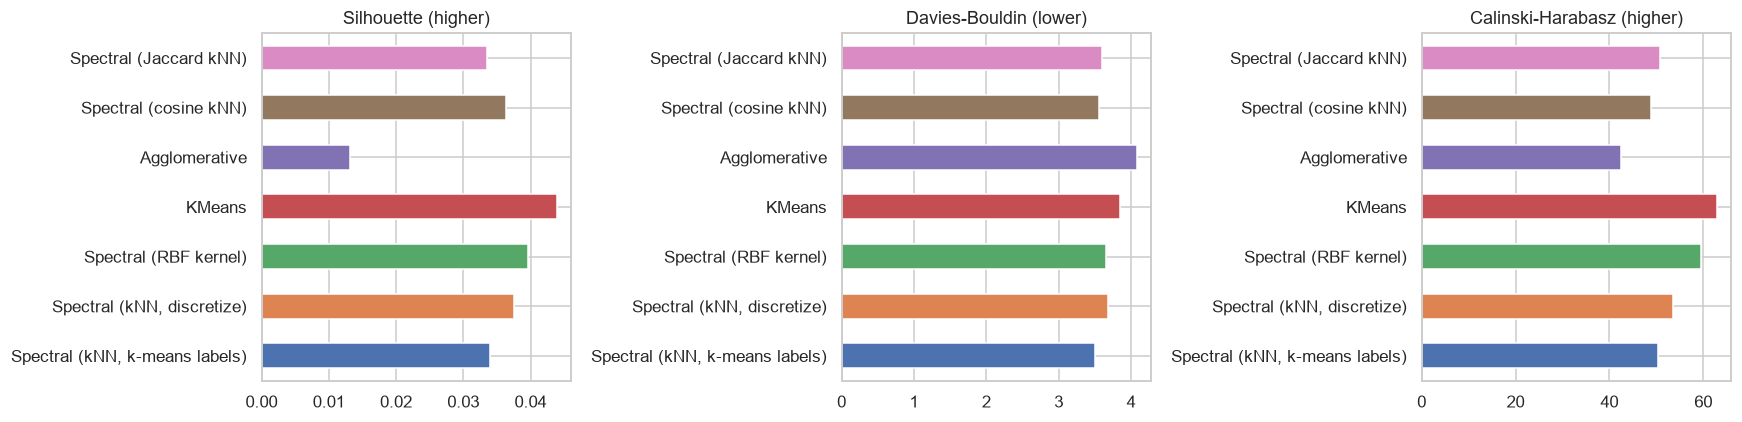

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Silhouette (higher)", "Davies-Bouldin (lower)", "Calinski-Harabasz (higher)"]):
    metrics.set_index("Method")[col].plot.barh(ax=ax, color=sns.color_palette("deep", len(metrics)))
    ax.set_title(col); ax.set_ylabel("")
plt.tight_layout(); plt.show()

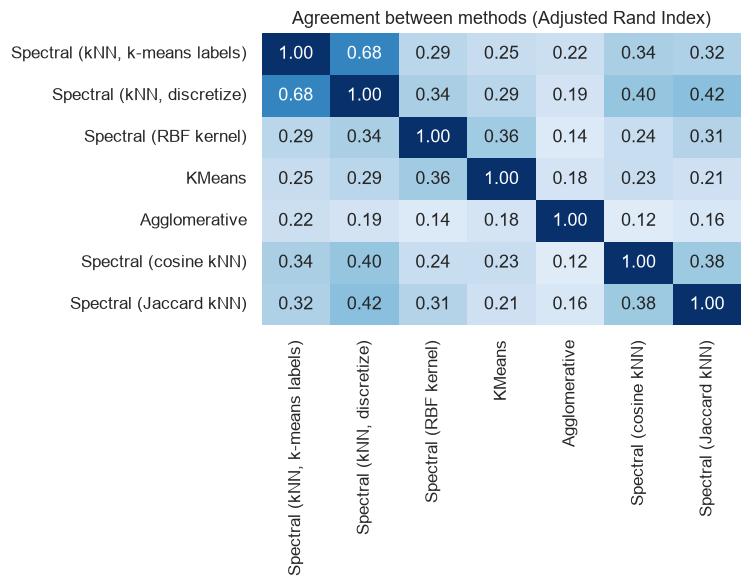

In [14]:
ari = evaluation.agreement(labels)
plt.figure(figsize=(7, 5.5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.title("Agreement between methods (Adjusted Rand Index)"); plt.tight_layout(); plt.show()

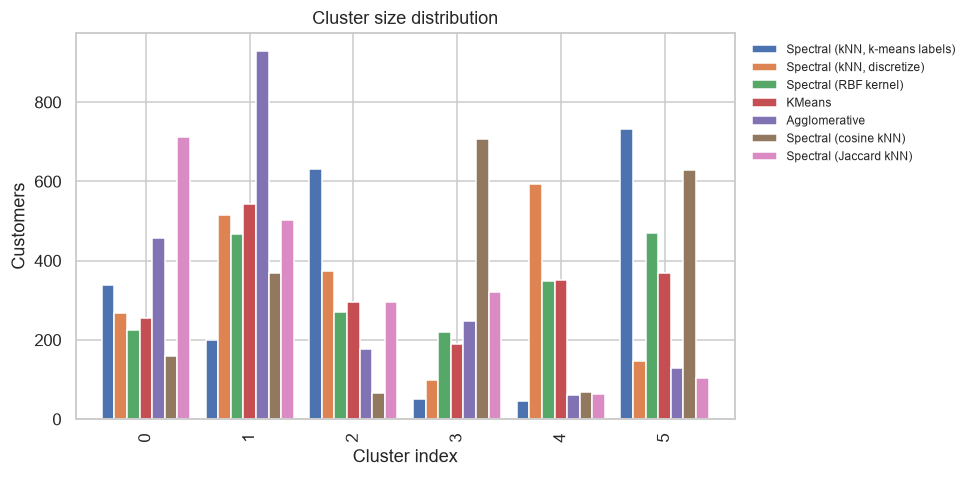

In [15]:
plots.size_bars(labels)
plt.show()

## 8. Visualising the clusters: PCA and t-SNE

PCA is a fast linear projection. t-SNE preserves local neighbourhoods and often makes structure clearer, but it is slower,
its distances are not exact, and a 2-D picture of 50 dimensions always hides information, so heavy overlap does not prove the
clusters are poor.

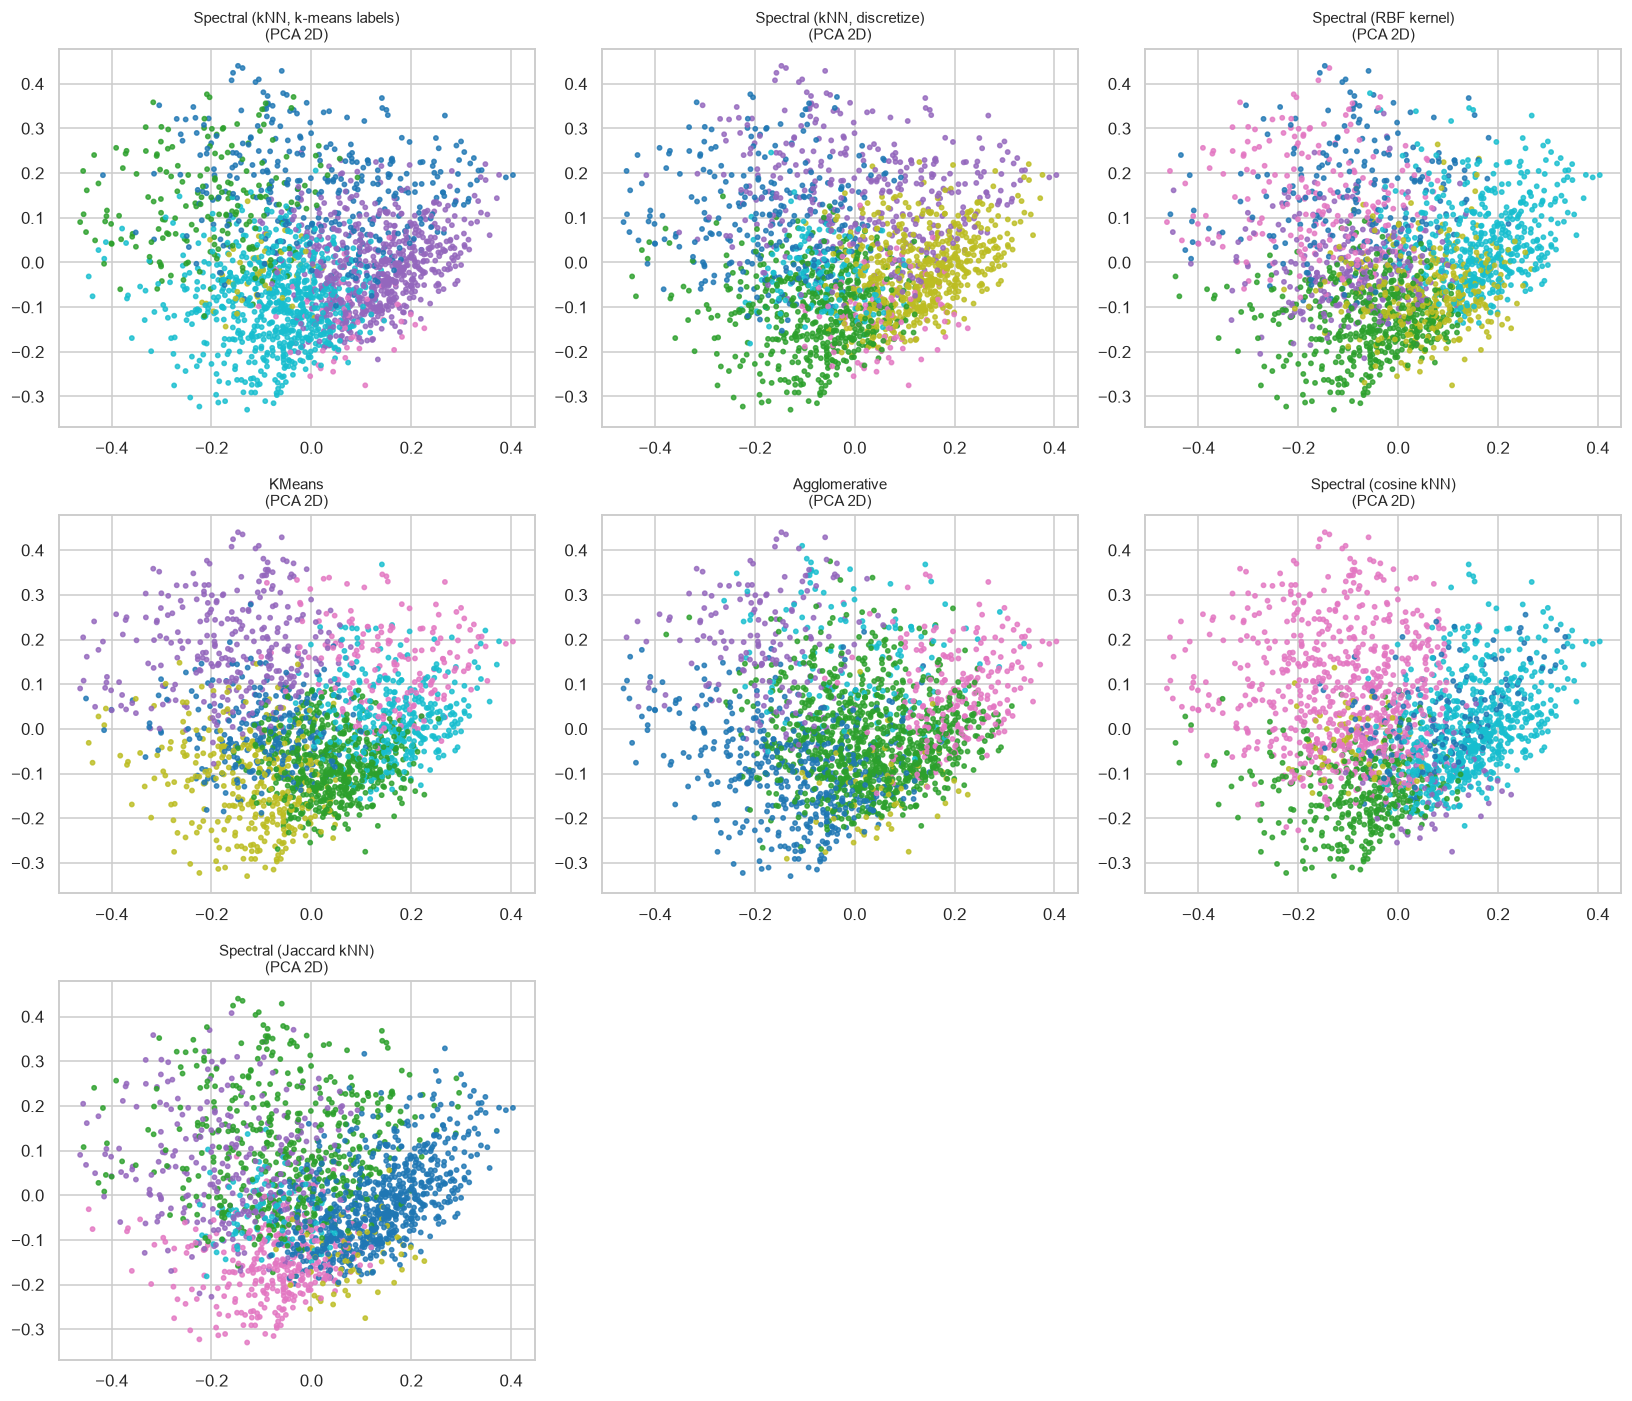

In [16]:
pca_xy = plots.embed_2d(fs.X_reduced, "pca")
plots.scatter_grid(pca_xy, labels, "PCA 2D")
plt.show()

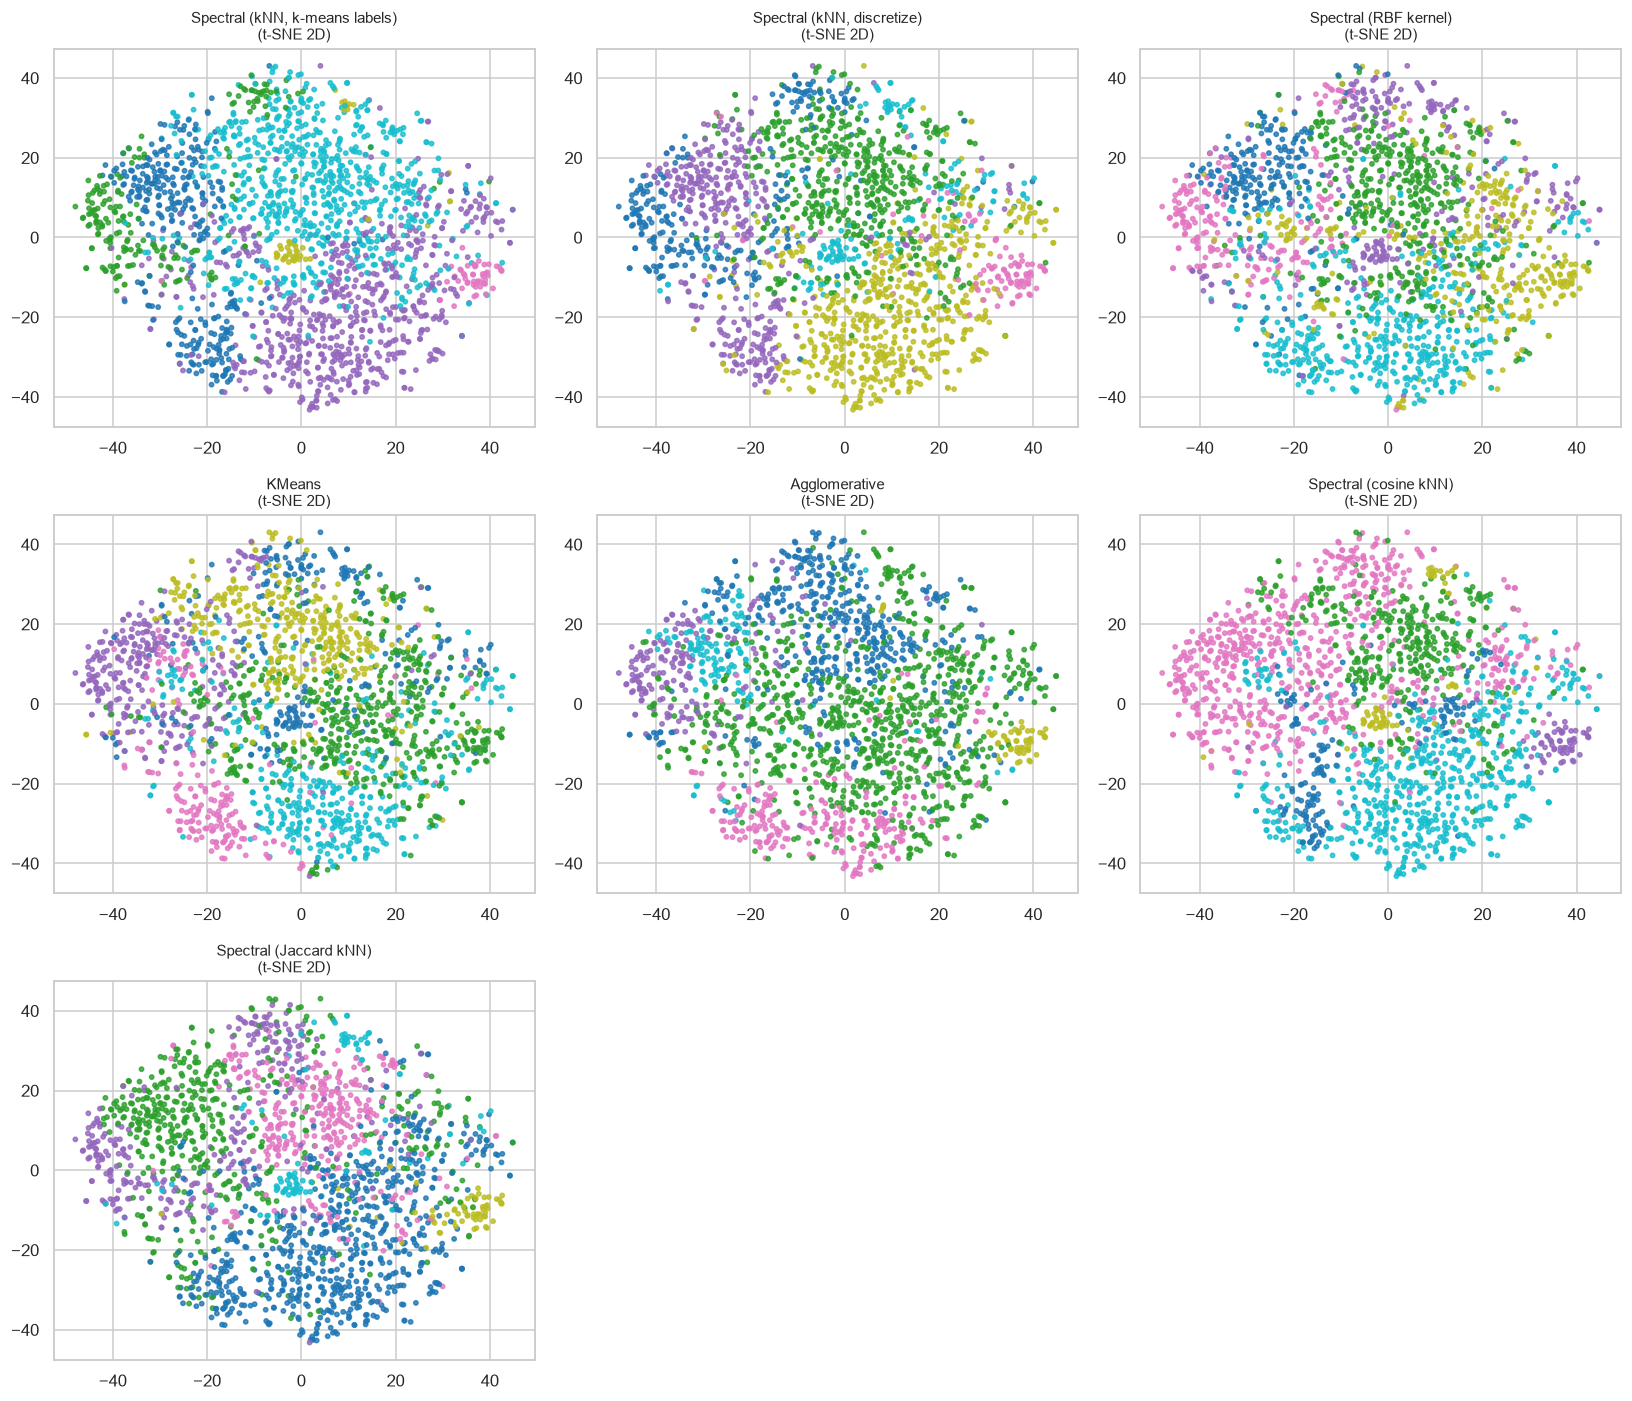

In [17]:
tsne_xy = plots.embed_2d(fs.X_reduced, "tsne")
plots.scatter_grid(tsne_xy, labels, "t-SNE 2D")
plt.show()

## 9. Testing the similarity measure

The project hypothesised that cosine or Jaccard similarity would give better spectral clusters than plain Euclidean distance on sparse
retail data. The table compares the three spectral variants that differ only in similarity.

In [18]:
sim_rows = ["Spectral (kNN, k-means labels)", "Spectral (cosine kNN)", "Spectral (Jaccard kNN)", "KMeans"]
metrics.set_index("Method").loc[sim_rows, ["Silhouette (higher)", "Silhouette cosine (higher)",
                                            "Davies-Bouldin (lower)", "Calinski-Harabasz (higher)"]].round(3)

,Silhouette (higher),Silhouette cosine (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher)
Method,,,,
"Spectral (kNN, k-means labels)",0.034,0.001,3.504,50.451
Spectral (cosine kNN),0.036,0.059,3.553,48.790
Spectral (Jaccard kNN),0.034,0.023,3.595,50.836
KMeans,0.044,0.047,3.841,62.841


Note that the *cosine silhouette* column is partly built in for the cosine variant, because that variant was clustered with cosine
similarity, so it should not be read as proof that cosine is better.

## 10. Profiling the segments

Numbers become useful when each cluster is described in business terms: how much its customers spend, how often they order, how many
different products they buy, and which products define them (share of the cluster that bought the product, and lift, the factor by
which that exceeds the average customer).

In [19]:
METHOD = "KMeans"
profiling.segment_summary(df, fs.customers, labels[METHOD])

,Cluster,customers,mean_spend,median_spend,mean_orders,mean_products,mean_order_value,share_of_customers
0,0,255,3347.82,1353.31,6.68,97.33,443.23,0.13
1,1,542,1912.41,775.95,4.72,55.86,400.88,0.27
2,2,295,8639.64,3387.43,16.26,208.88,467.20,0.15
3,3,189,6185.46,2247.31,11.08,159.15,451.81,0.09
4,4,351,2614.51,1507.26,6.68,116.91,429.02,0.18
5,5,368,1877.35,1016.86,5.76,81.47,321.50,0.18


In [20]:
desc = df.drop_duplicates("StockCode").set_index("StockCode")["Description"].to_dict()
top = evaluation.top_products_per_cluster(fs.binary, fs.products, labels[METHOD], desc, top_n=5)
for c, g in top.groupby("Cluster"):
    print(f"\nCluster {c}")
    print(g[["Description", "Share of cluster", "Lift"]].to_string(index=False))


Cluster 0
                        Description  Share of cluster  Lift
   PACK OF 72 RETRO SPOT CAKE CASES             0.780  3.07
 PACK OF 60 PINK PAISLEY CAKE CASES             0.498  2.97
        60 TEATIME FAIRY CAKE CASES             0.463  2.53
        PACK OF 72 SKULL CAKE CASES             0.357  3.08
SET OF 72 RETRO SPOT PAPER  DOILIES             0.345  3.12

Cluster 1
                     Description  Share of cluster  Lift
        REGENCY CAKESTAND 3 TIER             0.297  1.06
ROSES REGENCY TEACUP AND SAUCER              0.157  1.38
 GREEN REGENCY TEACUP AND SAUCER             0.148  1.45
  PINK REGENCY TEACUP AND SAUCER             0.127  1.45
    REX CASH+CARRY JUMBO SHOPPER             0.181  0.98

Cluster 2
                Description  Share of cluster  Lift
    LUNCHBAG PINK RETROSPOT             0.651  4.20
        LUNCH BAG CARS BLUE             0.651  3.97
  LUNCHBAG SPACEBOY DESIGN              0.678  3.80
     LUNCHBAG SUKI  DESIGN              0.617  4.14
JUMBO

In [21]:
METHOD = "Spectral (kNN, k-means labels)"
spec_top = evaluation.top_products_per_cluster(fs.binary, fs.products, labels[METHOD], desc, top_n=4)
sizes = np.bincount(labels[METHOD])
for c, g in spec_top.groupby("Cluster"):
    print(f"\nCluster {c}  ({sizes[c]} customers)")
    print(g[["Description", "Share of cluster", "Lift"]].to_string(index=False))


Cluster 0  (338 customers)
                    Description  Share of cluster  Lift
    GIN + TONIC DIET METAL SIGN             0.521  3.93
     COOK WITH WINE METAL SIGN              0.473  4.19
HAND OVER THE CHOCOLATE   SIGN              0.470  4.20
  PLEASE ONE PERSON  METAL SIGN             0.518  3.65

Cluster 1  (200 customers)
              Description  Share of cluster  Lift
LUNCHBAG SPACEBOY DESIGN              0.690  3.87
   LUNCHBAG SUKI  DESIGN              0.605  4.06
     LUNCH BAG RED SPOTTY             0.660  3.60
  LUNCHBAG PINK RETROSPOT             0.605  3.90

Cluster 2  (631 customers)
                       Description  Share of cluster  Lift
WHITE HANGING HEART T-LIGHT HOLDER             0.390  1.19
             HEART OF WICKER SMALL             0.241  1.21
   NATURAL SLATE HEART CHALKBOARD              0.212  1.08
             HEART OF WICKER LARGE             0.204  1.12

Cluster 3  (51 customers)
                     Description  Share of cluster  Lift
  PINK 

## 11. Product groups for cross-selling

The same machinery run on the transposed matrix groups *products* that the same customers buy. A nearest-neighbour lookup then answers
"customers who bought X also bought...".

In [22]:
pf = products.make_product_features(df)
pgroups = products.cluster_products(pf, 8)
print({m: sorted(np.bincount(l).tolist()) for m, l in pgroups.items()})
products.group_table(pf, pgroups["KMeans"], desc, top_n=4).head(24)

{'KMeans': [43, 56, 91, 103, 139, 165, 177, 226], 'Spectral (kNN)': [10, 20, 20, 26, 28, 31, 56, 809], 'Spectral (Jaccard kNN)': [16, 20, 31, 33, 65, 89, 167, 579]}


,Group,Group size,StockCode,Description,Customers
0,0,56,85099B,JUMBO BAG RED WHITE SPOTTY,915
1,0,56,20725,LUNCH BAG RED SPOTTY,806
2,0,56,22382,LUNCHBAG SPACEBOY DESIGN,755
3,0,56,20727,LUNCH BAG BLACK SKULL.,676
4,1,226,22086,PAPER CHAIN KIT 50'S CHRISTMAS,865
5,1,226,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,679
6,1,226,22077,6 RIBBONS RUSTIC CHARM,650
7,1,226,22585,PACK OF 6 BIRDY GIFT TAGS,584
8,2,43,21181,PLEASE ONE PERSON METAL SIGN,571
9,2,43,21175,GIN + TONIC DIET METAL SIGN,534


In [23]:
example = pf.products[int(np.argmax(pf.popularity))]          # the most popular product
print("Most popular product:", example, desc.get(example, ""))
products.similar_products(pf, example, desc, n=8)

Most popular product: 85123A WHITE HANGING HEART T-LIGHT HOLDER


,StockCode,Description,Similarity
0,21733,RED HANGING HEART T-LIGHT HOLDER,0.958
1,22469,HEART OF WICKER SMALL,0.931
2,22189,CREAM HEART CARD HOLDER,0.930
3,22470,HEART OF WICKER LARGE,0.910
4,22464,HANGING METAL HEART LANTERN,0.878
5,22188,BLACK HEART CARD HOLDER,0.877
6,22457,NATURAL SLATE HEART CHALKBOARD,0.870
7,84836,ZINC METAL HEART DECORATION,0.867


## 12. Reproducibility check

With fixed seeds, the pipeline must return identical cluster assignments and metrics when run again.

In [24]:
fs2 = features.make_features(df, MIN_PRODUCTS_PER_CUSTOMER, MIN_CUSTOMERS_PER_PRODUCT,
                             MAX_CUSTOMERS, MAX_PRODUCTS, N_COMPONENTS, SEED, WEIGHTING)
labels2 = clustering.run_all(fs2.X_reduced, K, n_neighbors=10, M=fs2.binary, seed=SEED)
same = {m: bool(np.array_equal(labels[m], labels2[m])) for m in labels}
print(same)
assert all(same.values()), "results are not reproducible"

{'Spectral (kNN, k-means labels)': True, 'Spectral (kNN, discretize)': True, 'Spectral (RBF kernel)': True, 'KMeans': True, 'Agglomerative': True, 'Spectral (cosine kNN)': True, 'Spectral (Jaccard kNN)': True}


## 13. Conclusions

The statements below describe the run on the full Online Retail II file with the default settings (k = 6, 2,000 customers, 500 products,
binary values). They are not valid for the synthetic demo data.

1. **Spectral clustering did not clearly beat K-Means.** K-Means had the best silhouette (0.044) and Calinski-Harabasz score (62.8); the
   spectral kNN variant had the best Davies-Bouldin score (3.50). Agglomerative clustering was weakest on all three metrics.
2. **All scores are low.** Silhouette stayed below 0.05 for every method and was almost flat across k = 2 to 10, so customers
   overlap heavily and do not fall into sharply separated groups.
3. **Spectral clustering found small niche groups that K-Means missed**, such as a 51-customer group of Regency tea-set buyers with lift of
   8 to 10, but it also produced very uneven cluster sizes (47 to 733 customers). K-Means gave more balanced clusters.
4. **Some segments are real and nameable**: novelty metal-sign buyers, children's lunch-bag buyers, cake-case and party-baking buyers.
   Two large clusters are generalists with lift close to 1.
5. **The similarity-measure hypothesis was only weakly supported.** Cosine improved silhouette slightly (0.036 against 0.034) but not
   Davies-Bouldin; Jaccard gave no improvement.
6. **Product grouping:** K-Means gave usable groups (43 to 226 products). Both spectral variants put most products in one giant group
   because the neighbour graph chains popular products together.

**Limitations.** Internal metrics are computed in the same reduced space the algorithms were fitted in, which favours compact clusters;
only 36% of the variance survives the SVD; spectral clustering was run on a 2,000-customer sample; and there is no ground truth,
so segment quality rests on interpretation.

**Next steps.** Add recency, frequency and monetary features; test stability over several random samples; try more neighbours or a different
graph for spectral clustering; and validate the segments with the retailer's own marketing knowledge.